# Online Retail Sales Dataset Analysis

## Importing libraries
The following libraries are used throughout the project:
- **pandas** – loading, cleaning and summarising tabular data.
- **numpy** – numerical calculations.
- **matplotlib** and **seaborn** – static visualisations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data

In [2]:
df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


The data has loaded correctly: each row is one product on an invoice, showing the quantity, unit price, customer and country. The next section assesses the quality of this raw data before any cleaning is done.

## Data quality assessment
The raw data is checked for problems before cleaning. Nothing is changed in this section.

In [3]:
df.shape

(541909, 8)

The dataset has **541,909 rows** and **8 columns**.

In [4]:
df.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

`InvoiceDate` is already a date, so it can be used for time analysis. `CustomerID` is a decimal number because it has missing values;

In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


`Quantity` and `UnitPrice` both have **negative minimums** and **very large maximums**, so the data contains invalid rows and outliers. The data runs from **1 Dec 2010 to 9 Dec 2011**, so December 2011 is incomplete.

In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

`CustomerID` is missing in **135,080 rows** and `Description` in **1,454 rows**.

In [7]:
df.shape[0] - df.drop_duplicates().shape[0]

5268

There are **5,268 duplicate rows**, which would count the same sale twice.

In [8]:
df[df['Quantity'] < 0].shape

(10624, 8)

There are **10,624 rows with a negative quantity**. These are cancelled orders or stock adjustments, not real sales.

In [9]:
df[df['UnitPrice'] <= 0].shape

(2517, 8)

There are **2,517 rows with a price of £0 or less**, which add no real revenue.

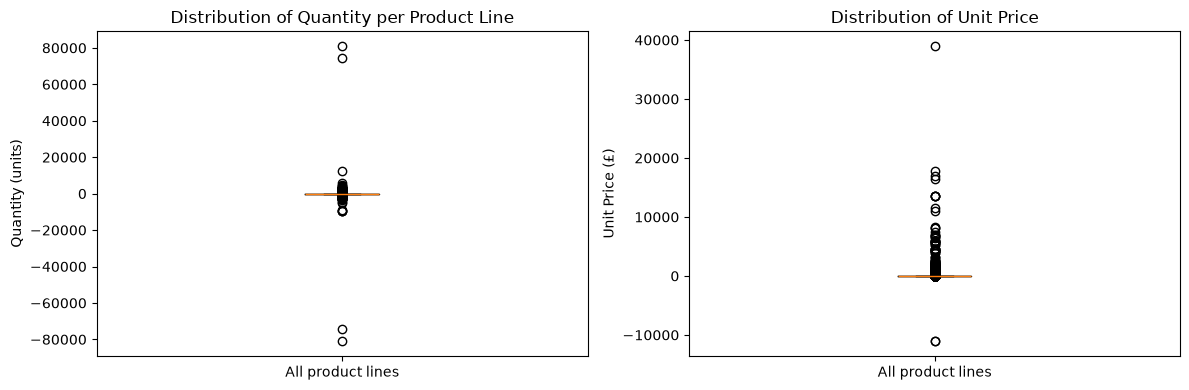

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(df['Quantity'])
axes[0].set_title('Distribution of Quantity per Product Line')
axes[0].set_ylabel('Quantity (units)')
axes[0].set_xticklabels(['All product lines'])

axes[1].boxplot(df['UnitPrice'])
axes[1].set_title('Distribution of Unit Price')
axes[1].set_ylabel('Unit Price (£)')
axes[1].set_xticklabels(['All product lines'])

plt.tight_layout()
plt.show()

A boxplot shows the normal range of values and marks extreme values as dots. Most values sit close to zero, but a few are extremely far away. These **outliers** would distort averages and charts.

### Summary of issues
| Issue | Rows |
|---|---|
| Missing `CustomerID` | 135,080 |
| Missing `Description` | 1,454 |
| Duplicate rows | 5,268 |
| Negative quantities | 10,624 |
| Price of £0 or less | 2,517 |
| Outliers in `Quantity` and `UnitPrice` | a few extreme values |

These issues are fixed in the next section.

## Data cleaning and preparation

In [11]:
df_clean = df.copy()

### Missing values
- **`CustomerID`:** filled with `0`, meaning "unknown customer". These are real sales, and removing about 25% of the data would make revenue, product and country figures too low. Customer-level analysis will leave out `CustomerID = 0`.
- **`Description`:** rows are removed. Without a name the product cannot be identified, and it is only 0.3% of the data.

`CustomerID` is filled first, so `dropna()` only removes the rows with no description.

In [12]:
df_clean['CustomerID'] = df_clean['CustomerID'].fillna(0)
df_clean = df_clean.dropna()

In [13]:
df_clean.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [14]:
df_clean.shape

(540455, 8)

No missing values remain. 1,454 rows without a description were removed, leaving **540,455 rows**.

### Duplicates
Exact duplicate rows are removed because they would count the same sale twice.

In [15]:
df_clean = df_clean.drop_duplicates()
df_clean.shape

(535187, 8)

**5,268 duplicate rows** were removed, leaving **535,187 rows**.

### Cancelled orders and negative quantities
Only rows with a quantity above zero are kept. Negative quantities are cancelled orders or stock adjustments, not real sales, so they would wrongly reduce revenue.

In [16]:
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean.shape

(525462, 8)

**9,725 rows** were removed, leaving **525,462 rows**.

### Zero and negative prices
Only rows with a price above zero are kept. A price of £0 or less is a free item, an error or an accounting entry, and adds no real revenue.

In [17]:
df_clean = df_clean[df_clean['UnitPrice'] > 0]
df_clean.shape

(524878, 8)

**584 rows** were removed, leaving **524,878 rows**.

In [18]:
df_clean[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,524878.000000,524878.000000
mean,10.616600,3.922573
std,156.280031,36.093028
min,1.000000,0.001000
25%,1.000000,1.250000
50%,4.000000,2.080000
75%,11.000000,4.130000
max,80995.000000,13541.330000


The minimum quantity is now **1** and the minimum price is above **£0**, so all invalid rows are gone. The maximums are still very large, so the outliers are handled next.

### Outliers
Outliers are only removed when they are clearly errors or not real products. Large orders that are believable for a wholesaler are kept, because they are real revenue.

In [19]:
df_clean[df_clean['Quantity'] > 10000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [20]:
df[df['Quantity'] < -10000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


Only **2 rows** have a quantity above 10,000 (74,215 and 80,995 units). The original data shows that both orders were cancelled with the same negative quantity, so they were ordered by mistake. They are removed.

In [21]:
df_clean = df_clean[df_clean['Quantity'] < 10000]
df_clean.shape

(524876, 8)

In [22]:
df_clean[df_clean['UnitPrice'] > 1000]['Description'].value_counts()

Description
DOTCOM POSTAGE     28
Manual             23
AMAZON FEE          1
POSTAGE             1
Adjust bad debt     1
Name: count, dtype: int64

Every price above £1,000 belongs to a **non-product entry**: postage, manual adjustments, fees or accounting entries. These are not products, so they would distort product revenue and prices. They are removed using their stock codes.

In [23]:
df_clean = df_clean[df_clean['StockCode'] != 'POST']
df_clean = df_clean[df_clean['StockCode'] != 'DOT']
df_clean = df_clean[df_clean['StockCode'] != 'M']
df_clean = df_clean[df_clean['StockCode'] != 'C2']
df_clean = df_clean[df_clean['StockCode'] != 'BANK CHARGES']
df_clean = df_clean[df_clean['StockCode'] != 'AMAZONFEE']
df_clean = df_clean[df_clean['StockCode'] != 'B']
df_clean = df_clean[df_clean['StockCode'] != 'S']
df_clean.shape

(522570, 8)

**2,306 non-product rows** were removed, leaving **522,570 rows**. The codes are: `POST` and `DOT` (postage), `M` (manual), `C2` (carriage), `BANK CHARGES`, `AMAZONFEE`, `B` (bad debt adjustment) and `S` (samples).

In [24]:
df_clean[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,522570.000000,522570.000000
mean,10.345429,3.275054
std,37.852897,4.396064
min,1.000000,0.001000
25%,1.000000,1.250000
50%,4.000000,2.080000
75%,12.000000,4.130000
max,4800.000000,649.500000


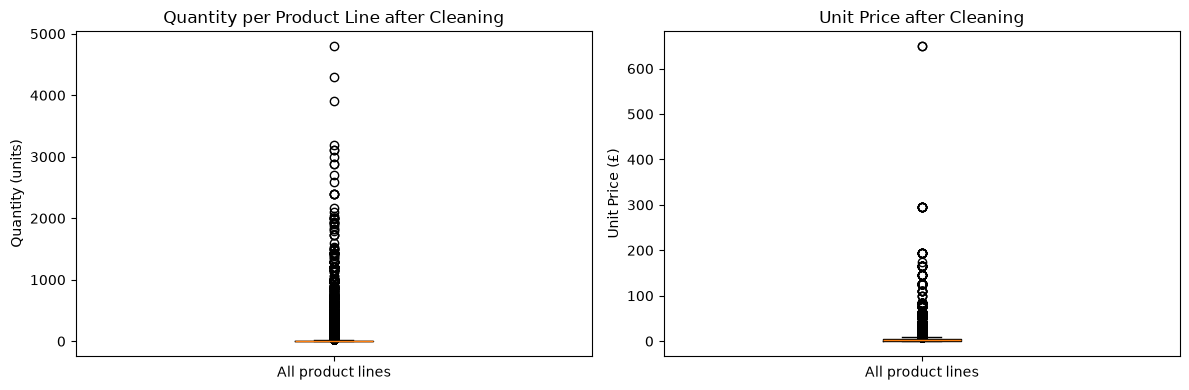

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(df_clean['Quantity'])
axes[0].set_title('Quantity per Product Line after Cleaning')
axes[0].set_ylabel('Quantity (units)')
axes[0].set_xticklabels(['All product lines'])

axes[1].boxplot(df_clean['UnitPrice'])
axes[1].set_title('Unit Price after Cleaning')
axes[1].set_ylabel('Unit Price (£)')
axes[1].set_xticklabels(['All product lines'])

plt.tight_layout()
plt.show()

The maximum quantity is now **4,800 units** and the maximum price is **£649.50**, both real products. The boxplots still show values above the box, but these are genuine large orders and expensive items, so they are kept. The median (4 units, £2.08) did not change, so the typical sale is unaffected.

### Data types and new fields
`InvoiceDate` was already read as a date, so it does not need converting. `CustomerID` is changed to a whole number, because it is an ID and has no missing values left.

In [26]:
df_clean['CustomerID'] = df_clean['CustomerID'].astype('int64')

A new **`Revenue`** column is created by multiplying quantity by unit price. This is the value of each product line in pounds (£), and it is the main measure used in the rest of the analysis.

In [27]:
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

In [28]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [29]:
df_clean.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              int64
Country                   str
Revenue               float64
dtype: object

`CustomerID` is now a whole number (`int64`) and `Revenue` is a decimal number in pounds (`float64`). For example, 6 units at £2.55 give a revenue of £15.30.

## Exploratory data analysis
This section explores the cleaned data to answer the business questions: which products, which countries and which periods bring in the most revenue.

### Summary statistics

In [30]:
df_clean[['Quantity', 'UnitPrice', 'Revenue']].describe()

,Quantity,UnitPrice,Revenue
count,522570.000000,522570.000000,522570.000000
mean,10.345429,3.275054,19.140507
std,37.852897,4.396064,84.664725
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.900000
75%,12.000000,4.130000,17.700000
max,4800.000000,649.500000,38970.000000


In [31]:
df_clean['Revenue'].sum()

np.float64(10002254.483)

Summary statistics give a quick numerical picture of a typical sale before looking at charts.

- **Total revenue** in the cleaned data is about **£10.0 million**.
- A typical product line is small: the **median is 4 units** at **£2.08** each, bringing in **£9.90**.
- The **mean revenue (£19.14) is about double the median (£9.90)**. This means a small number of large orders pull the average up, so the median is a better description of a typical sale.
- The largest single product line brought in **£38,970**, far above the 75th percentile of £17.70. Large wholesale orders are rare but very valuable.

### Revenue over time
Revenue is first added up for each invoice time, which gives the value of each order over the year.

In [32]:
revenue_by_time = df_clean.groupby('InvoiceDate')['Revenue'].sum()
revenue_by_time.describe()

count    18330.000000
mean       545.676731
std       1230.365177
min          0.380000
25%        160.935000
50%        309.400000
75%        532.930000
max      52940.940000
Name: Revenue, dtype: float64

There are **18,330 invoice times**. A typical order is worth **£309** (median), but some are worth over **£50,000**, so the raw values jump around too much to show a clear trend. A **moving average** over 500 orders smooths out these jumps.

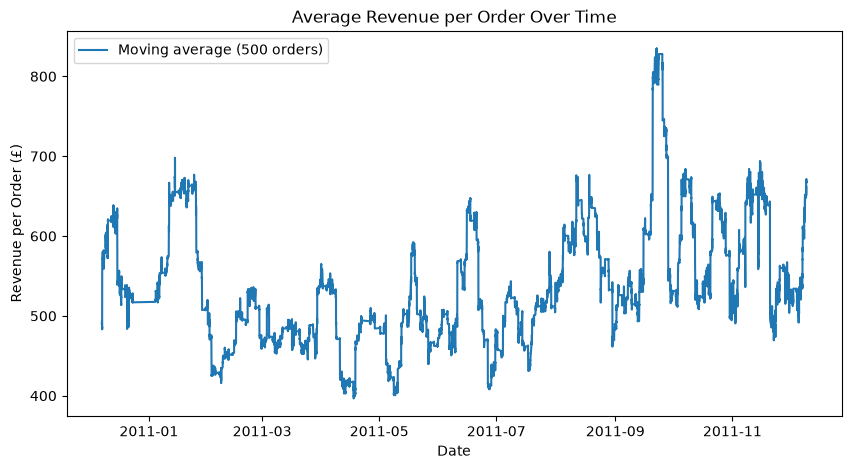

In [33]:
rolling_revenue = revenue_by_time.rolling(window=500).mean()

plt.figure(figsize=(10,5))
plt.plot(rolling_revenue, label='Moving average (500 orders)')
plt.title('Average Revenue per Order Over Time')
plt.xlabel('Date')
plt.ylabel('Revenue per Order (£)')
plt.legend()
plt.show()

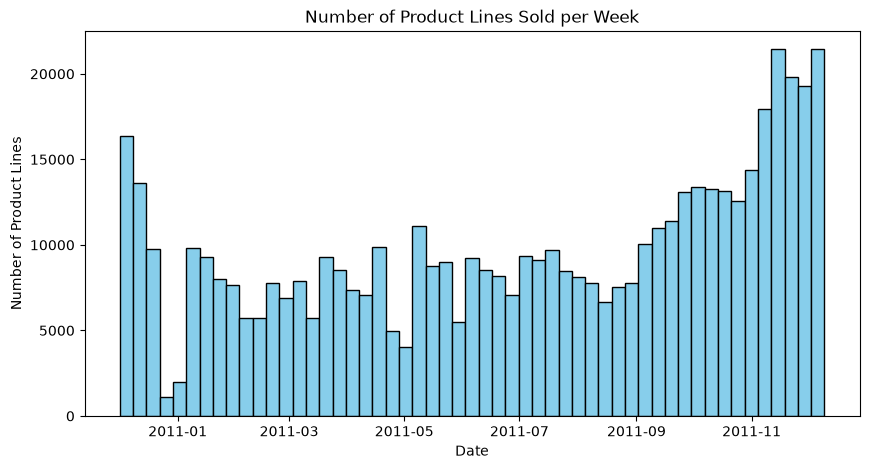

In [34]:
plt.figure(figsize=(10,5))
plt.hist(df_clean['InvoiceDate'], bins=53, color='skyblue', edgecolor='black')
plt.title('Number of Product Lines Sold per Week')
plt.xlabel('Date')
plt.ylabel('Number of Product Lines')
plt.show()

A **line chart** was chosen for the moving average because it shows how a value changes continuously over time. A **histogram** of invoice dates was chosen to count how many product lines were sold in each week of the year.

- **Order value** stays mostly between **£450 and £650** all year. It is lowest from February to July and higher in the autumn, with a short peak of about **£830** in late September.
- **Number of sales** is steady at around 5,000–10,000 product lines a week from January to August, then rises sharply from September to a peak of over **20,000 a week in November**.
- Sales almost stop in the last two weeks of December 2010, which is most likely the Christmas closure.

**Insight:** the autumn growth comes mainly from **more orders**, not much bigger orders. This matches a gift wholesaler whose customers stock up for Christmas, so stock and staff should be planned for September to November.

### Top products by revenue
Revenue is added up for each product to find which products bring in the most money.

In [35]:
product_revenue = df_clean.groupby('Description', as_index=False)[['Revenue']].sum()
product_revenue.shape

(4018, 2)

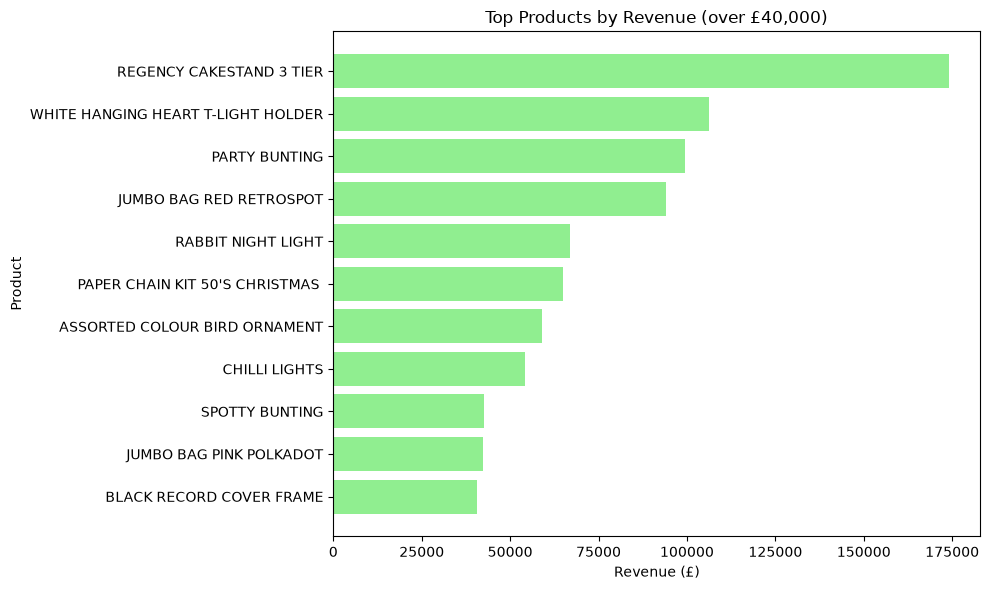

In [36]:
top_products = product_revenue[product_revenue['Revenue'] > 40000]
top_products = top_products.sort_values(by=['Revenue'])

plt.figure(figsize=(10,6))
plt.barh(top_products['Description'], top_products['Revenue'], color='lightgreen')
plt.title('Top Products by Revenue (over £40,000)')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

A **horizontal bar chart** was chosen because it compares amounts across categories, and long product names are easy to read on the side. The bars are sorted so the best seller is at the top.

- Out of **4,018 products**, only **11** brought in more than £40,000.
- The **Regency Cakestand 3 Tier** is the clear best seller at about **£174,000**, much more than the next product (about £106,000).
- Most top products are **decorations and party items** (bunting, lights, ornaments, a Christmas paper chain kit) and **bags**, which fits a gift wholesaler.

**Insight:** a small group of products brings in a large share of revenue, so these should always be kept in stock and could be promoted together.

### Revenue by country
The United Kingdom is the company's home market, so its revenue is compared with all other countries first.

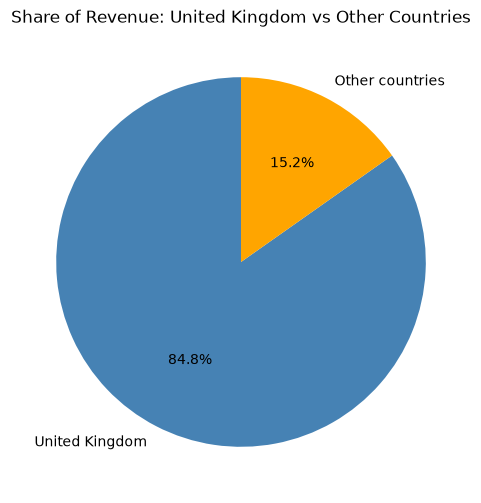

In [37]:
other_countries = df_clean[df_clean['Country'] != 'United Kingdom']

uk_revenue = df_clean[df_clean['Country'] == 'United Kingdom']['Revenue'].sum()
other_revenue = other_countries['Revenue'].sum()

plt.figure(figsize=(6,6))
plt.pie([uk_revenue, other_revenue], labels=['United Kingdom', 'Other countries'], autopct="%1.1f%%", startangle=90, colors=['steelblue', 'orange'])
plt.title('Share of Revenue: United Kingdom vs Other Countries')
plt.show()

In [38]:
country_revenue = other_countries.groupby('Country', as_index=False)[['Revenue']].sum()
country_revenue.shape

(37, 2)

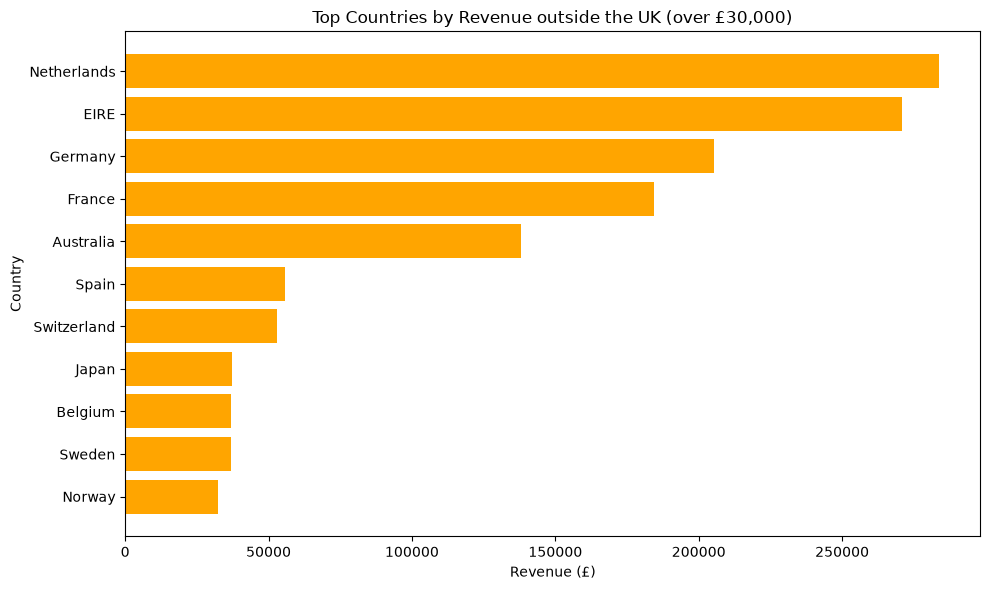

In [39]:
top_countries = country_revenue[country_revenue['Revenue'] > 30000]
top_countries = top_countries.sort_values(by=['Revenue'])

plt.figure(figsize=(10,6))
plt.barh(top_countries['Country'], top_countries['Revenue'], color='orange')
plt.title('Top Countries by Revenue outside the UK (over £30,000)')
plt.xlabel('Revenue (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

A **pie chart** was chosen for the UK vs other countries split because there are only two parts and it shows their share of the whole at a glance. A **horizontal bar chart** was then used to compare the other countries, because the UK is so large that it would hide the differences between them on the same chart.

- The **United Kingdom** brings in **84.8%** of all revenue, so the business depends heavily on its home market.
- The other **37 countries** together bring in **15.2%**.
- Outside the UK, the most important markets are the **Netherlands** and **EIRE** (Ireland), each with about **£270,000–£285,000**, followed by **Germany**, **France** and **Australia**.
- Most of the top international customers are **close European neighbours**.

**Insight:** relying on one country is a risk. The Netherlands, Ireland, Germany and France are already strong markets and are the most promising places to grow international sales.

### Distribution of revenue per product line
This looks at how the value of a single product line is spread. Lines under £100 are shown, because a few very large lines would squeeze all the others into one bar.

In [40]:
small_lines = df_clean[df_clean['Revenue'] < 100]
small_lines.shape[0] / df_clean.shape[0] * 100

97.57219128537804

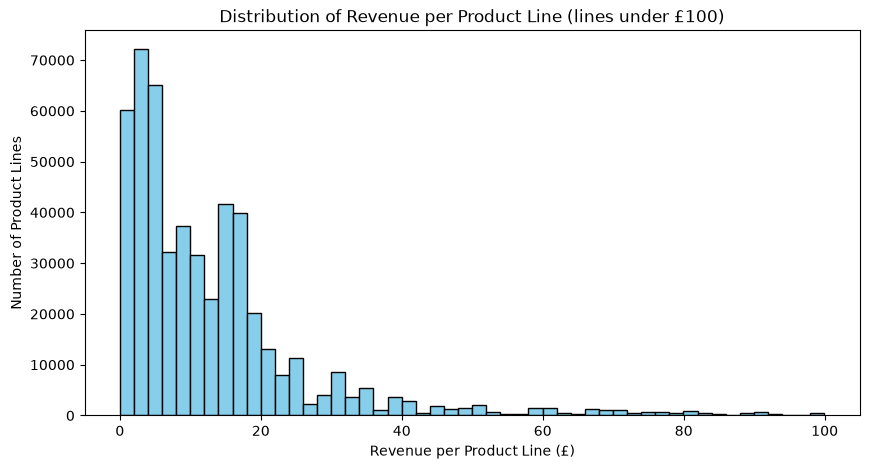

In [41]:
plt.figure(figsize=(10,5))
plt.hist(small_lines['Revenue'], bins=50, color='skyblue', edgecolor='black')
plt.title('Distribution of Revenue per Product Line (lines under £100)')
plt.xlabel('Revenue per Product Line (£)')
plt.ylabel('Number of Product Lines')
plt.show()

A **histogram** was chosen because it shows how values are spread, by counting how many product lines fall into each price band.

- **97.6%** of all product lines are worth **less than £100**.
- The distribution is **right-skewed**: most lines are worth under **£20**, the most common value is just a few pounds, and the number of lines drops quickly as the value goes up.
- There is a second peak at about **£15–£18**, which is likely caused by common pack sizes (for example 12 items at around £1.25–£1.45).

**Insight:** the business makes most of its sales through many small, low-value lines, while the rare large lines (seen in the summary statistics) add a lot of revenue. Both small regular customers and large bulk buyers matter.

### Relationship between quantity, price and revenue

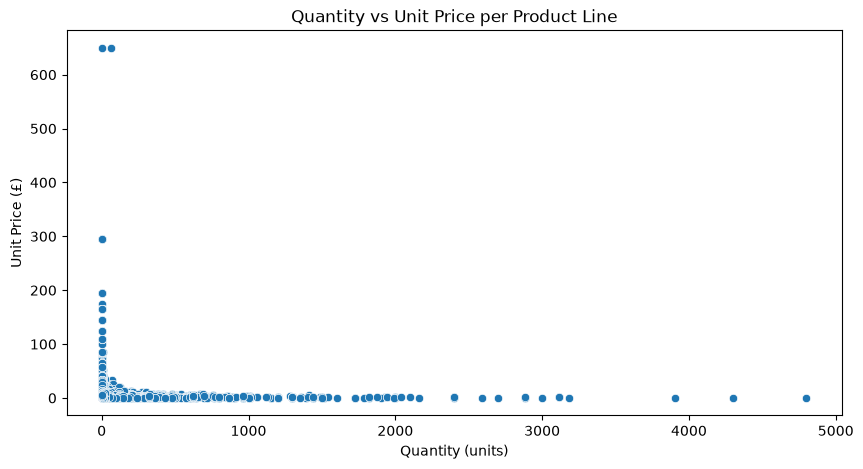

In [42]:
plt.figure(figsize=(10,5))
sns.scatterplot(x='Quantity', y='UnitPrice', data=df_clean)
plt.title('Quantity vs Unit Price per Product Line')
plt.xlabel('Quantity (units)')
plt.ylabel('Unit Price (£)')
plt.show()

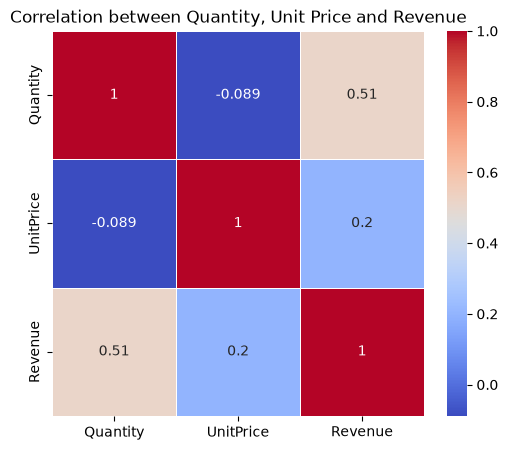

In [43]:
corr = df_clean[['Quantity', 'UnitPrice', 'Revenue']].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title('Correlation between Quantity, Unit Price and Revenue')
plt.show()

A **scatter plot** was chosen because it shows how two numerical values relate to each other, with one dot per product line. A **correlation heatmap** was added to measure these relationships as numbers between -1 and 1, where values close to 0 mean there is little or no link.

- The scatter plot has an **"L" shape**: expensive items are bought in small quantities, and very large quantities are only bought for cheap items. No product line has both a high price and a high quantity.
- **Quantity and revenue** have a moderate positive correlation (**0.51**): buying more units is the main driver of a larger order.
- **Unit price and revenue** have a weak correlation (**0.20**): expensive items do not bring in much more revenue per line, because they are bought in small numbers.
- **Quantity and unit price** have almost no correlation (**-0.09**), with a very slight tendency for bulk items to be cheaper.

**Insight:** revenue grows mainly by selling **more units**, not by selling more expensive items. Encouraging larger orders, for example with bulk discounts on popular cheap products, is likely to increase revenue more than pushing high-priced items.

### Summary of findings
- **Time:** sales are steady for most of the year and rise sharply from September to a peak in November, driven by more orders before Christmas.
- **Products:** a small number of products, led by the Regency Cakestand 3 Tier, bring in the most revenue. Most of them are decorations, party items and bags.
- **Countries:** the United Kingdom brings in 84.8% of revenue. The Netherlands, Ireland, Germany and France are the strongest markets abroad.
- **Orders:** most product lines are small (under £20), and revenue is driven mainly by the number of units sold rather than by price.